# Week 9 · Topic 4 — Keeping Secrets Out of Code

**Mohammed Mohammed Alhaji** · CST1510 · 26 November 2026

**Box we are building: PROCESS, made safe, and kept that way**

Hashing protects passwords. This topic protects everything else — API keys,
tokens, anything that must never sit in a file you might commit.

> **Already know this?** Skip to the *Topic 4 Challenge*.

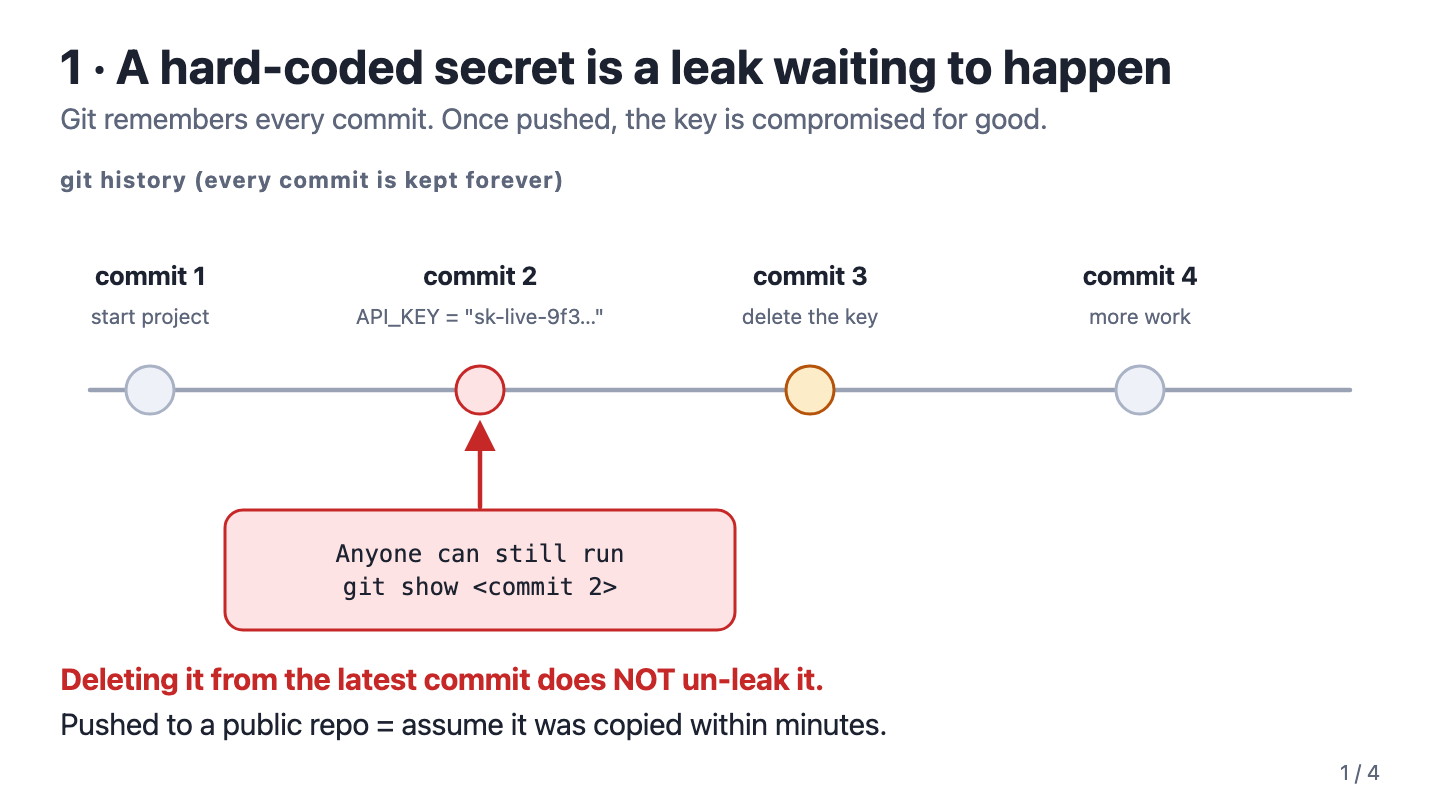

---
## 1. A hard-coded secret is a mistake, not a style issue

The moment it is pushed to a public repository, it is compromised — deleting
it later does not help, it is still in the commit history.

In [1]:
# BAD - never do this:
# API_KEY = "sk-abc123realsecretvalue"

print("see the comment above - nothing to run here")

see the comment above - nothing to run here


### Your turn
Explain in one sentence why deleting a leaked key from your latest commit does not fix the leak.

In [2]:
print("Deleting the latest copy does not revoke the key or remove copies already saved in Git history or other people's clones.")

Deleting the latest copy does not revoke the key or remove copies already saved in Git history or other people's clones.


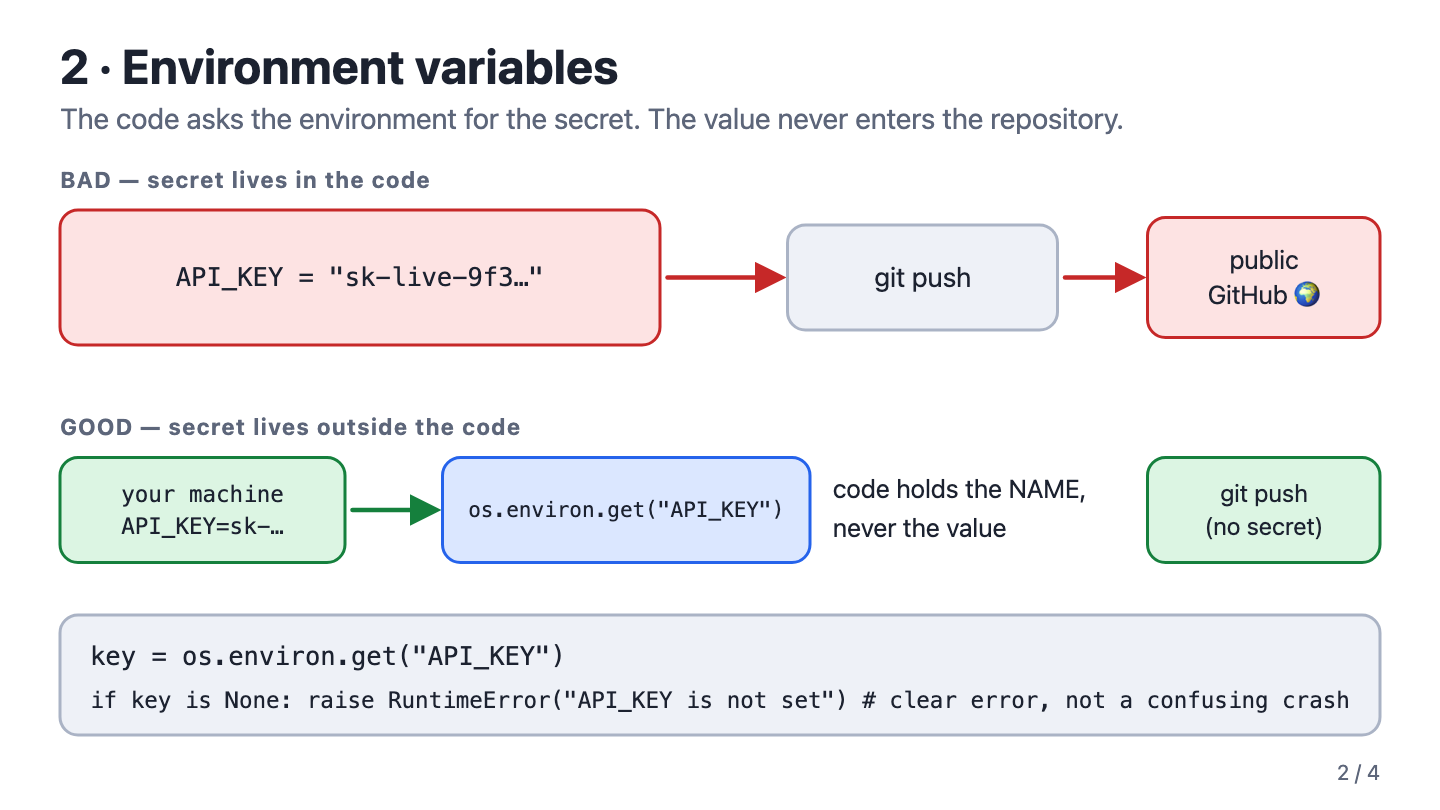

---
## 2. Environment variables — the secret lives outside your code

In [3]:
import os

api_key = os.environ.get("MY_API_KEY", "not set")
print("MY_API_KEY is set:", api_key != "not set")
# Check availability without displaying an actual credential.

MY_API_KEY is set: False


### Your turn
Set an environment variable in your terminal, then read it back with `os.environ.get()`.

In [4]:
import os
import subprocess
import sys

# Terminal equivalent on macOS or Linux:
# export CST1510_DEMO_SETTING=classroom-demo
# In PowerShell:
# $env:CST1510_DEMO_SETTING = "classroom-demo"
# Give a fresh Python process that same setting for this run.
environment = os.environ.copy()
environment["CST1510_DEMO_SETTING"] = "classroom-demo"
result = subprocess.run(
    [sys.executable, "-c", 'import os; print(os.environ.get("CST1510_DEMO_SETTING"))'],
    env=environment,
    capture_output=True,
    text=True,
    check=True,
)
print(result.stdout.strip())
assert result.stdout.strip() == "classroom-demo"

classroom-demo


A default like `"not set"` is fine for something optional. When a variable is *required* — the program genuinely cannot continue without it — raise a clear error instead of letting it fail later with a confusing message.

In [5]:
def require_env(name):
    """Return the named environment variable, or raise a clear error if it is missing."""
    value = os.environ.get(name)
    if value is None:
        raise RuntimeError(f"{name} is not set. Set it before running this.")
    return value

try:
    require_env("MY_API_KEY")
except RuntimeError as e:
    print("Caught it:", e)

Caught it: MY_API_KEY is not set. Set it before running this.


### Your turn
Write `require_env("HOME")` (or another variable you know is set on your machine) and check it returns the value instead of raising.

In [6]:
path_value = require_env("PATH")
print("PATH returned a value:", bool(path_value))
assert path_value == os.environ["PATH"]
# Check retrieval without printing personal folder paths.

PATH returned a value: True


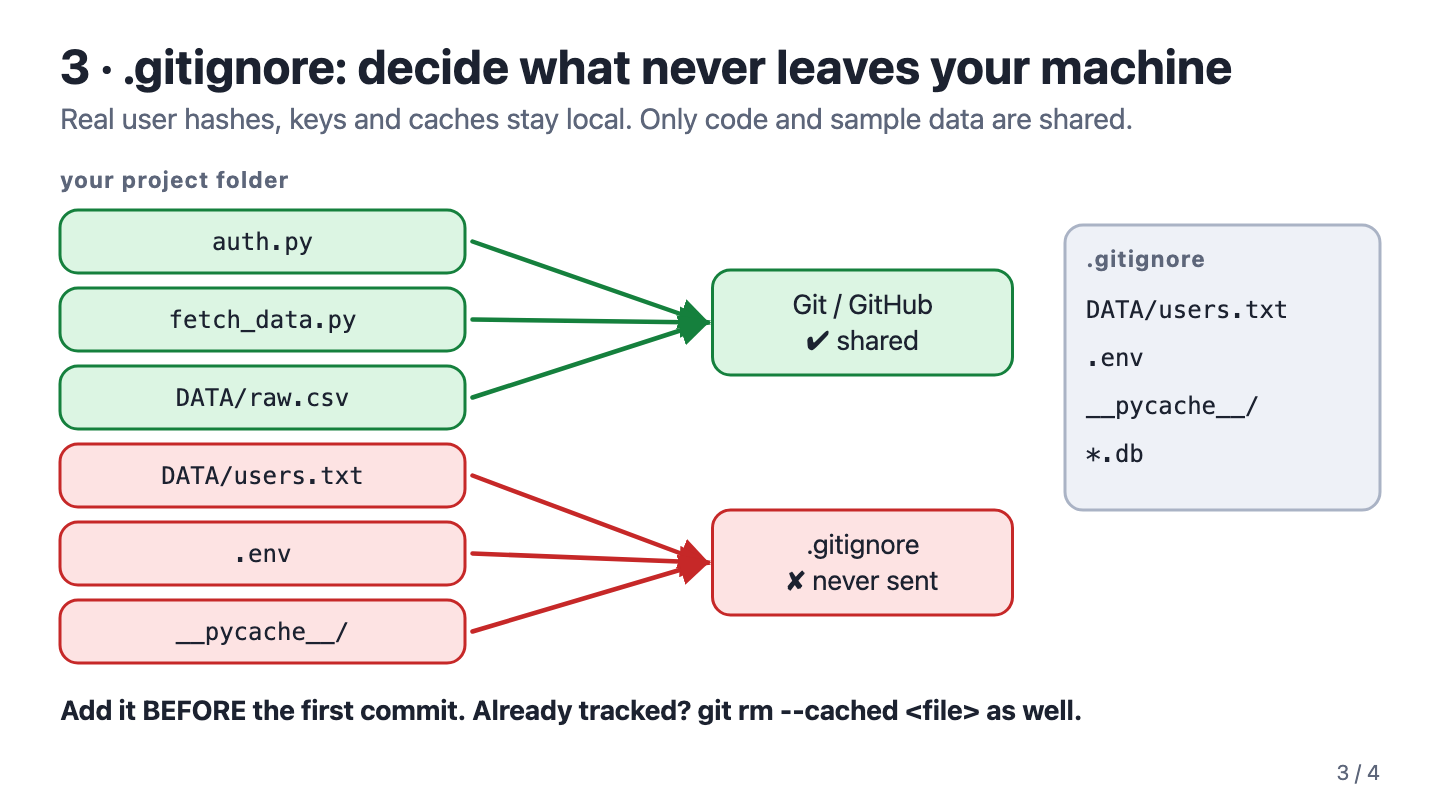

---
## 3. `.gitignore` — deciding what never gets tracked

Once your project has real accounts and real keys, these need to be in it.

In [7]:
gitignore_lines = ["*.db", "*.env", ".streamlit/secrets.toml", "__pycache__/", "users.txt"]
for line in gitignore_lines:
    print(line)

*.db
*.env
.streamlit/secrets.toml
__pycache__/
users.txt


### Your turn
Write a `.gitignore` file for your own `CST1510_CW2` folder, covering what applies so far.

In [8]:
from pathlib import Path
from tempfile import TemporaryDirectory

rules = [
    ".venv/",
    "__pycache__/",
    ".ipynb_checkpoints/",
    ".pytest_cache/",
    ".DS_Store",
    ".env",
    "*.env",
    "*.db",
    "DATA/app.db",
    "DATA/users.txt",
    "users.txt",
    ".streamlit/secrets.toml",
    "practice/",
]

# Practise writing the file in a temporary project folder.
# The actual CST1510_CW2 project already has the course's private-file rules.
with TemporaryDirectory() as folder:
    project = Path(folder) / "CST1510_CW2"
    project.mkdir()
    ignore_file = project / ".gitignore"
    ignore_file.write_text("\n".join(rules) + "\n", encoding="utf-8")
    print(ignore_file.read_text(encoding="utf-8"))
    assert "DATA/users.txt" in ignore_file.read_text(encoding="utf-8")
    assert ".streamlit/secrets.toml" in ignore_file.read_text(encoding="utf-8")
print("Temporary .gitignore exercise finished.")

.venv/
__pycache__/
.ipynb_checkpoints/
.pytest_cache/
.DS_Store
.env
*.env
*.db
DATA/app.db
DATA/users.txt
users.txt
.streamlit/secrets.toml
practice/

Temporary .gitignore exercise finished.


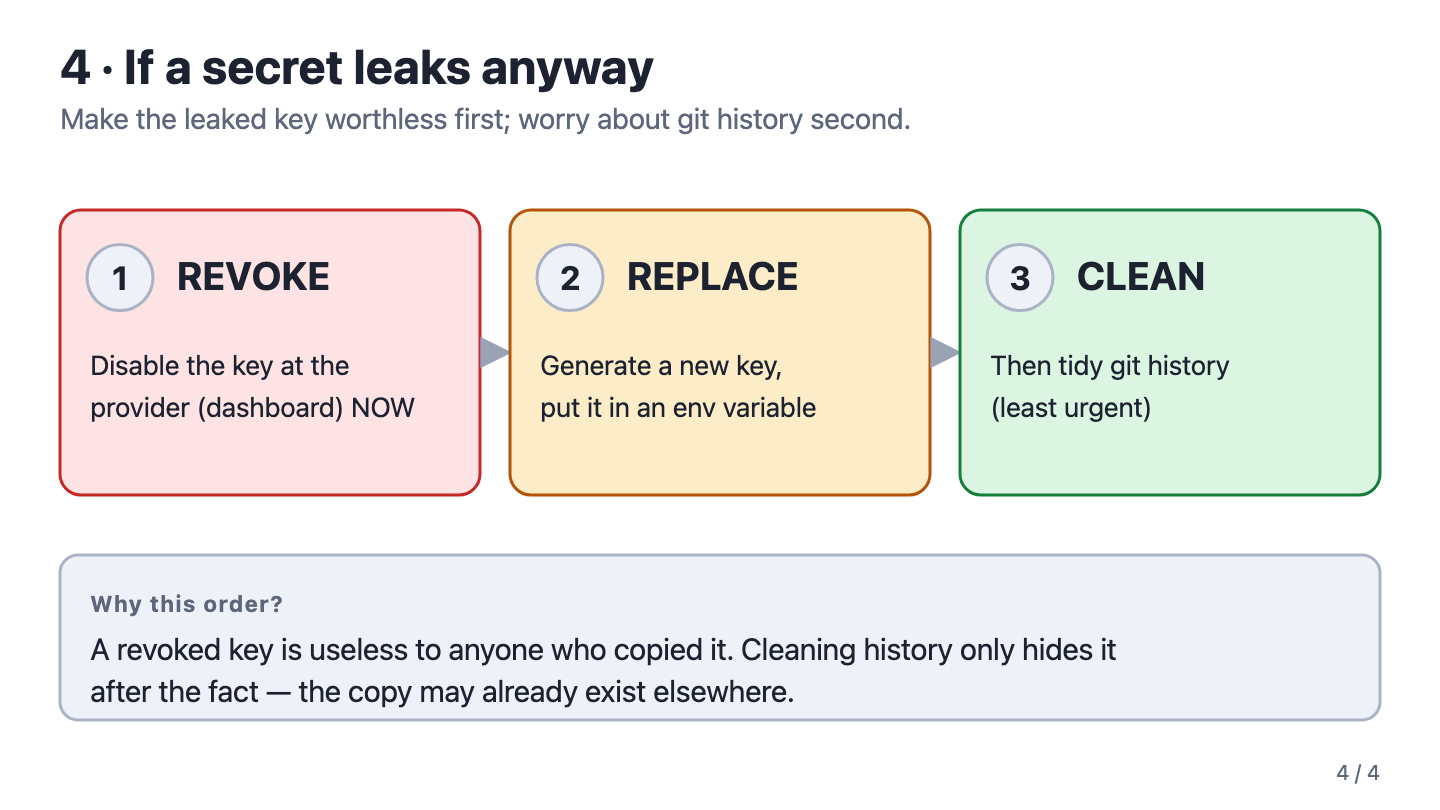

---
## 4. If a secret leaks anyway

Removing it from the latest commit is not enough — it is still readable in
history. Revoke the key at its source first, generate a new one, worry about
cleaning history second.

### Your turn
Name one place you would go to revoke a leaked API key for a service you use.

I would open GitHub's account settings, go to Developer settings and Personal access tokens, and revoke the affected token. I would then replace it wherever it was used.

---
## Topic 4 Challenge

Write a small script that reads a required environment variable and raises a
clear error (not a crash with a confusing traceback) if it is missing.

In [9]:
script = """
import os
import sys

def require_env(name):
    "Return a required value or raise a clear error when it is absent."
    value = os.environ.get(name)
    if not value:
        raise RuntimeError(f"{name} is missing. Set it before running this script.")
    return value

try:
    key = require_env("CST1510_REQUIRED_DEMO_KEY")
except RuntimeError as error:
    print(f"Cannot start: {error}")
    sys.exit(1)

print("Required setting loaded.")
"""

# Each subprocess gets its own environment. The notebook's environment stays intact.
missing_environment = os.environ.copy()
missing_environment.pop("CST1510_REQUIRED_DEMO_KEY", None)
missing = subprocess.run(
    [sys.executable, "-c", script],
    env=missing_environment,
    capture_output=True,
    text=True,
)
print("Missing setting:", missing.stdout.strip())
print("Exit status:", missing.returncode)
assert missing.returncode == 1
assert missing.stderr == ""

present_environment = missing_environment.copy()
present_environment["CST1510_REQUIRED_DEMO_KEY"] = "dummy-classroom-value"
present = subprocess.run(
    [sys.executable, "-c", script],
    env=present_environment,
    capture_output=True,
    text=True,
)
print("Present setting:", present.stdout.strip())
print("Exit status:", present.returncode)
assert present.returncode == 0
assert "dummy-classroom-value" not in present.stdout

Missing setting: Cannot start: CST1510_REQUIRED_DEMO_KEY is missing. Set it before running this script.
Exit status: 1
Present setting: Required setting loaded.
Exit status: 0


---
## Same idea, three fields

| Field | Looks like |
|---|---|
| **AI / Data Science** | keeping a Kaggle API token out of a notebook you might share |
| **Cyber Security** | keeping a threat-intel API key out of a public incident console repo |
| **IT** | keeping a monitoring service's token out of a committed config file |

---
## Common mistakes

| Mistake | What you see | Fix |
|---|---|---|
| committing a `.db` or `.txt` file full of real hashed users | it is now in your repository's history | add it to `.gitignore` *before* the first commit that includes it |
| assuming a private repo makes secrets safe | tutors, group members, and future public forks can still see it | treat every repo as if it could become public |
| hard-coding "just for testing" | it is easy to forget to remove before committing | use an environment variable from the start, even in testing |
| checking `.gitignore` after committing the file once | too late — it is already tracked | `git rm --cached <file>` is needed on top of `.gitignore` if this happens |
| defaulting a *required* variable to `"not set"` and carrying on | it fails later, somewhere confusing, instead of here | `raise` a clear error the moment you know it's missing |

## Go deeper

`examples/01_environment_variables.py` — os.environ, sensible defaults, raising on a missing required variable
`examples/02_gitignore_and_what_not_to_commit.py` — what belongs in .gitignore, and why

---
## Recap

| You can now | Using |
|---|---|
| keep a secret out of your code | `os.environ.get("NAME")` |
| refuse to continue without a required one | `raise RuntimeError(...)` |
| keep it out of your repository | `.gitignore` |
| respond correctly to a leak | revoke first, clean history second |

**You now have all of Week 9's tools.** Open last week's project and add a
login to it — nothing about it resets.